In [1]:
%matplotlib inline
import numpy as np
import random as rnd
import matplotlib.pyplot as plt
import time
from scipy.stats import wilcoxon

PART ONE

Part One aims to implement and evaluate a baseline local search algorithm using a Hill-Climber approach. This will be conducted using Instance One, this contains 28 models and 2 storage constraints. Each model has an associated utility and two storage capacities. This is a multi-dimensional knapsack problem as the objective is to select a combination of models to maximise the total utility without exceeding either storage requirement. 

In [2]:
def load_workload_instance(file_path):
    """
    Loads a hardware-constrained workload allocation dataset.
    
    Parameters:
        file_path (str): Path to the dataset plain text file (.txt).
        
    Returns:
        n (int): Number of candidate AI models.
        m (int): Number of hardware resource constraints.
        utilities (np.ndarray): 1D array of shape (n,) containing model utility scores (p_j).
        demands (np.ndarray): 2D array of shape (m, n) containing resource consumption demands (r_{i,j}).
        capacities (np.ndarray): 1D array of shape (m,) containing hardware capacity limits (b_i).
    """
    with open(file_path, 'r') as f:
        tokens = f.read().split()
        
    if not tokens:
        raise ValueError(f"Dataset file at '{file_path}' is empty or invalid.")
        
    n = int(tokens[0])
    m = int(tokens[1])
    idx = 2
    
    # Model utility scores (length n)
    utilities = np.array([float(x) for x in tokens[idx : idx + n]])
    idx += n
    
    # Resource demand matrix (shape m x n)
    demands = np.zeros((m, n))
    for i in range(m):
        demands[i, :] = [float(x) for x in tokens[idx : idx + n]]
        idx += n
        
    # Maximum hardware capacity limits (length m)
    capacities = np.array([float(x) for x in tokens[idx : idx + m]])
    
    return n, m, utilities, demands, capacities


if __name__ == "__main__":
    # Example usage demonstration
    sample_file = "multi_resource_n28_m2.txt"
    try:
        n, m, utilities, demands, capacities = load_workload_instance(sample_file)
        print("=== Dataset Ingestion Summary ===")
        print(f"Number of candidate models (n) : {n}")
        print(f"Number of resource bounds (m)  : {m}")
        print(f"Utility scores shape (p_j)     : {utilities.shape}")
        print(f"Resource demands shape (r_ij)  : {demands.shape}")
        print(f"Capacity limits (b_i)          : {capacities}")
    except FileNotFoundError:
        print(f"Please provide a valid path to '{sample_file}'.")


=== Dataset Ingestion Summary ===
Number of candidate models (n) : 28
Number of resource bounds (m)  : 2
Utility scores shape (p_j)     : (28,)
Resource demands shape (r_ij)  : (2, 28)
Capacity limits (b_i)          : [500. 500.]


Instance one was loaded and checked that there were 28 total models and 2 storage requirements. Each storage capacity is 500 and each model has a utility, and two storage requirements.

Creation of Fractional Demand (how much of each capacity each model uses), Model Utility/Capacity ratio, and an ordered list of models from best ratio to least for use in repair function later on.

In [3]:
#Calculates the total fraction of each capacity required by each model
fractionDemand = (demands / capacities[:, None]).sum(axis = 0)
#Calculates the priority sorting ratio by dividing a models utility by capacity demand
ratio = utilities / fractionDemand
#Sorts models by priority in descending order(model with highest utility-to-demand first)
modelsByRatio = list(np.argsort(-ratio))

Solution Representation
A solution is represented using a binary vector where each position corresponds to a model (28 positions for Instance One). A value of 1 indicates a model is deployed (selected) whilst a value of 0 indicates this is excluded (undeployed).

Objective
The objective for Part One is to maximise total utility whilst satisfying both resource constraints. As such solutions are evaluated in relation to total utility with an acceptable flag to signify when they are within resource constraints. 

Initial Solution Creation Function

In [4]:
def generateSolution(size, proportion):
    """ 
    function to create a random binary solution of size = size
    """
    solution = rnd.choices([0,1], weights = [proportion, 1 - proportion], k = size)
    return solution

To evaluate the total utility is calculated by summing the utilities of all deployed models. The total storage demand for each constraint is also found by summing the storage requirements of all deployed models. If neither storage capacity is exceeded, then the solution is considered to be feasible. 

Solution Evaluation Function

In [5]:
def evaluate(sol, storageMax, utilities, demands):
    """
    Evaluates a solution (sol) against storageMax (the capacities for the models) returning the total utility of the solution,
    capacity used for each capacity, and whether the solution is under all capacity limits.
    Input: Solution as a binary array and capacities as an array.
    Output: the total utility score, the total capacities used and whether the solution is under all allowed capacities. 
    """
    
    numItems = len(sol)
    numCapacities = len(storageMax)

    totalUtilities = sum( sol[i] * utilities [i] for i in range (numItems))
    #totalCapacities created to hold values for the different types of capacity
    totalCapacities = []
    
    for j in range(numCapacities):
        capacity = sum(sol[i] * demands[j][i] for i in range (numItems))
        totalCapacities.append(capacity)

    underCapacity = all(totalCapacities [j] <= storageMax [j] for j in range(numCapacities))
        
    
    return totalUtilities, totalCapacities, underCapacity

A starting solution is created with each model having a 10% chance of being deployed. A low initial deployment reduces the likelihood or generating an infeasible solution that exceeds one of the constraints.
To make sure the starting solution is feasible the solution is evaluated against the storage constraints. If the solution is infeasible, another random solution is generated until a feasible starting pont is found. This ensure that the Hill-Climber always begins from a valid solution.

Starting Solution Creation Function for hillClimber

In [6]:
def startingSolution (size, storageMax, utilities, storageReqs):
    """
    Creates a random acceptable solution, retrying until solution satifies all storage maximums.
    Input:Size of required solution (size), Maximum Storage Capacities (storageMax), utilities of models, and storageReqs of models.
    Output: The Solution, Utility Value, Resource Usage and number of evalutions taken to form an acceptable solution.
    """
    used = 0
    while True:
        solution = generateSolution(size, 0.9)
        utility, demand, acceptable = evaluate(solution, storageMax, utilities, storageReqs)
        used += 1
        if acceptable:
            return solution, utility, demand, used

Mutation Functions

Two mutation functions were used in Part One:

Bit Flip: This mutation selects a random position in the solution and alters a single model from 0 to 1 or 1 to 0. This allows the algorithm to explore nearby solutions by introducing or removing a specific model. However, this can get stuck in local optima due to only one change per iteration.

Swap: This mutation selects a currently deployed model (1) and a currently undeployed model (0) and exchanges their status. This maintains the number of deployed models whilst allowing the algorithm to explore alternative combinations. 

Combining Both: Using both types of mutation provides a balance of small local changes and more substantial step changes to increase the variety of solutions explored. 

Neighbour (Bit Flip) Creation Function

In [7]:
def createNeighbour(sol):
    """
    Takes in a solution (sol) and creates a bit flip mutation (one model change) of the solution.
    Input: A given solution
    Output: A bit flip mutation (neighbour) solution for the solution given.
    """
    neighbour = sol.copy()
    i = rnd.randint(0, len(sol) - 1)
    neighbour [i] = 0 if sol[i] == 1 else 1
    return neighbour

Swap Mutation Creation Function

In [8]:
def swapMutation(sol):
    """
    Takes in a solution (sol) and creates a swap mutation of the solution. This is where one deployed model is
    undeployed and one undeployed model becomes deployed (two model change). Number of deployed models remains the same.
    If all models deployed or no models deployed then the solution remains unchanged.
    Input: A given solution
    Output: A swap mutated copy for the solution given.
    """
    mutant = sol.copy()
    size = len(sol)
    active = [i for i in range(size) if sol[i] == 1]
    dormant = [i for i in range(size) if sol[i] == 0]
    if active and dormant:
        mutant[rnd.choice(active)] = 0
        mutant[rnd.choice(dormant)] = 1
    return mutant

Repair
A solution generated may exceed one or more of the resource constraints and therefore no longer be a good candidate. Rather than losing this solution repair aims to restore feasibility by removing models until the resource consumption is back within capacities. This approach is inspired by the feasibility repair method proposed by Chu and Beasley[1]. 

This works in two stages:
Stage 1: Restoration of Feasibility by Removing Models
When a solution exceeds one or more constraints, models are removed until all capacity demands fall within limits. This is guided by a utility to demand ratio, prioritising removal of models with low utility per demand.

Stage 2: Reintroduction of Undeployed Models
Once the solution is feasible the repair mechanism attempts to reintroduce undeployed models. This is done in descending order of their utility per demand. Each model is only added if it does not cause any resource capacity to become exceeded. 
This is important as Stage 1 may create unused capacity so by reintroducing models lost utility can be recovered and the quality of the solution improved. 


A repair based constraint handling strategy was selected to allow the Hill-Climber (and Genetic Algorithm) to explore a wider range of solutions without permanently discarding infeasible mutations and ensures that the solutions considered for final selection are always feasible for all hardware constraints. The two stage process balances feasibility with utility preservation.

Limitations
While the repair function improves solution quality and feasibility it does not guarantee that the optimal solution will be found. The utility to demand ratio may not accurately represent the contribution of the model across all capacities. This could be a model that appears overall very efficient but could consume a substantial amount of a specific capacity and a minimal amount of all others. The repair function also introduces additional computational usage as the resource consumption must be recalculated during removal (step 1) and reintroduction (step 2).

Repair Solution Creation Function

In [9]:
def repairSolution(sol, storageMax, storageReqs, sortedModels):
    """
    Takes in a solution (sol) and makes it acceptable (all capacities equal to or below maximum capacity given. 
    Works in two phases:
    Removal Phase: undeploys models with lowest utility by capacity until each capacity is no longer exceeded.
    Insertion Phase: depoys skipped models with best utility by capacity ratios that still fit within each capacity.
    Input: A given solution
    Output: A repaired copy of the solution that is within all capacity limits. 
    """
    sol = sol.copy()
    usage = np.dot(storageReqs, sol)
    for j in sortedModels[::-1]:
        if np.all(usage <= storageMax):
            break
        if sol[j] == 1:
            sol [j] = 0
            usage = usage - storageReqs [:, j]
    for j in sortedModels:
        if sol [j] == 0 and np.all(usage + storageReqs[:, j] <= storageMax):
            sol[j] = 1
            usage = usage + storageReqs [:, j]
    return sol
                                   
            
        

The Hill-Climber starts from a feasible solution and then evaluates neighbouring solutions to find improvements on the overall utility. When an improvement is found, that is within the capacity constraints this is taken forward as the new solution. This is an iterative process where the search moves towards locally better solutions. This can lead to the algorithm becoming trapped in a local optimum with all neighbours being worse than a given solution even though a better solution exists. 
The swap mutator is off by default but when engaged activates half of the time instead of the bit flip mutator. This allows for a greater degree of variation in the solutions. 
The repair function is not used by default but when active it takes in the proposed new solution and turns infeasible solutions feasible. It also improves feasible solutions by allocating models until a capacity is reached. 
Finally, a restart option is available to allow the function to escape when it is trapped at a local maximum. This works by taking a completely new solution and using it for the Hill-Climber. The trace is only appended if the new solution has a better utility than the current best utility. 

Hill-Climber Function

In [10]:
def hillClimber(maxEvals, storageMax , storageReqs, utilities, sortedModel, swap = False, restartAfter = None, repair = False):
    """
    Hill-Climber function with optional swap mutation, optional restart and optional repair. Stops after maxEval number of evaluations
    by counting every call to the evaluate function (including starting solutions).
    Inputs: Max number of evaluations, storage capacities, storage demands, utilities and models ranked by ratio
    Output: Best utility, it's resource usage, the best solution and trace of best utility after each evaluation
    """
    size = len(utilities)
    solution, utility, demand, used = startingSolution(size, storageMax, utilities, storageReqs)
    evals = used
    bestUtility, bestDemand = utility, demand
    bestSolution = solution.copy()
    trace = [bestUtility] * used
    stuck = 0
    
    while evals < maxEvals:
        if swap and rnd.random() < 0.5:
            neighbour = swapMutation(solution)
        else:
            neighbour = createNeighbour(solution)

        if repair:
            neighbour = repairSolution(neighbour, storageMax, storageReqs, sortedModel)
        neighbourUtility, neighbourDemand, neighbourAcceptable = evaluate(neighbour, storageMax, utilities, storageReqs)
        evals += 1
        if neighbourAcceptable and neighbourUtility >= utility:
                if neighbourUtility > utility:
                    stuck = 0
                else:
                    stuck += 1
                solution = neighbour.copy()
                utility = neighbourUtility
                demand = neighbourDemand
        else:
            stuck += 1
        if utility > bestUtility:
            bestUtility, bestDemand = utility, demand
            bestSolution = solution.copy()
        if restartAfter is not None and stuck >= restartAfter and evals < maxEvals:
            solution, utility, demand, used = startingSolution(size, storageMax, utilities, storageReqs)
            evals += used
            if utility > bestUtility and evals <= maxEvals :
                bestUtility, bestDemand = utility, demand
                bestSolution = solution.copy()
            trace.extend([bestUtility] * used)
            stuck = 0
    
        trace.append(bestUtility)
    return bestUtility, bestDemand, bestSolution, trace[:maxEvals]

Neutral Moving:
The Hill Climber function allows for both improving and neutral feasible neighbouring solutions by accepting solutions with utility that is equal to or greater than the current solution. This allows the algorithm to explore different model combinations without an immediate increase in utility. This can help the search move along plateaus to find improvements that would be unavailable to requiring improving moves. However, by accepting neutral moves, this also can increase the number of evaluations spent exploring space that does not improve utility.

Check that Repair Always Gives an Acceptable Solution.

In [11]:
for i in range(10000):
    newSolution = generateSolution(n,0.5)
    assert evaluate(repairSolution(newSolution, capacities, demands, modelsByRatio), capacities, utilities, demands) [2]
print("Repair always gives an acceptable solution")

Repair always gives an acceptable solution


Swap always keeps total number of deployed models the same and only changes 2. Expect both sums to come back equal and 2 values to be different.

In [12]:
solutionA = generateSolution(n, 0.9)
solutionB = swapMutation(solutionA)
print(sum(solutionA),sum(solutionB))
print(sum(value != value2 for value, value2 in zip(solutionA, solutionB)))

0 0
0


Check that random seeds returning the same details

In [13]:
rnd.seed(7); np.random.seed(7)
run1= hillClimber(1000, capacities, demands, utilities, modelsByRatio, True, 25, True)
rnd.seed(7); np.random.seed(7)
run2= hillClimber(1000, capacities, demands, utilities, modelsByRatio, True, 25, True)
print("repeatable:", run1 == run2)

repeatable: True


Part One Experiment

To evaluate the performance of the Hill-Climbing algorithm, a series of experiments were conducted using Instance One.
Six different configurations were tested to investigate the effect of different mutation strategies and feasibility handling:
1. Bit Flip Only.
2. Bit Flip with periodic restarts.
3. Bit Flip and Swap Mutation.
4. Bit Flip and Swap Mutation with periodic restarts.
5. Bit Flip and Swap Mutation with repair.
6. Bit Flip and Swap Mutation with periodic restarts and repair.

Each configuration was evaluated across 30 runs using random seed 42 as the starting point. 
Performance was assessed using minimum utility, maximum utility, mean utility, standard deviation and time across runs.
This experiment aims to investigate the effect of differing mutation functions, set restarts and feasibility repair on the performance of the baseline Hill-Climber algorithm.

In [14]:
def runExperiment (storageMax , storageReqs, utilities, sortedModel, swap = False, restartAfter = None, repair = False, numRuns = 30, maxEvals = 1000):
    """
    Runes the Hill-Climber numRuns times, each from its own seed (starting seed set to 42 for replicability) and each time with the same maximum number
    of evaluations so that comparisons are fair.
    Input: Storage capacities, storage demands, utilities and models ranked by ratio, swap switch, restart switch, repair switch, number of runs
    and maximum number of evaluations.
    Output: arrays for best utilities, traces, best solutions, and run times
    """
    bestList, traces, times, solutions = [], [], [], []
    for run in range(numRuns):
        np.random.seed (42 + run)
        rnd.seed(42 + run)
        start = time.time()
        best, usage, solution, trace = hillClimber(maxEvals,storageMax, storageReqs, utilities, sortedModel, swap, restartAfter, repair)
        times.append(time.time() - start)
        bestList.append(best)
        traces.append(trace)
        solutions.append(solution)
    return np.array(bestList), np.array(traces), np.array(solutions), np.array(times)
        
        
        

In [15]:
for restart in [1, 2, 5, 10, 15 , 20, 25, 50, 100, 200, 500, None]:
    findings = runExperiment(capacities, demands, utilities, modelsByRatio, swap = False, restartAfter = restart)[0]
    print(f"Restart After = {restart}: Mean = {findings.mean():.0f} Min = {findings.min():.0f} Standard Deviation = {findings.std():.0f}")

Restart After = 1: Mean = 101810 Min = 87263 Standard Deviation = 8688
Restart After = 2: Mean = 108698 Min = 98273 Standard Deviation = 5983
Restart After = 5: Mean = 111203 Min = 100246 Standard Deviation = 5929
Restart After = 10: Mean = 109720 Min = 94678 Standard Deviation = 6160
Restart After = 15: Mean = 111423 Min = 101587 Standard Deviation = 5378
Restart After = 20: Mean = 108660 Min = 97094 Standard Deviation = 5452
Restart After = 25: Mean = 107223 Min = 94222 Standard Deviation = 6714
Restart After = 50: Mean = 105878 Min = 91686 Standard Deviation = 7463
Restart After = 100: Mean = 103667 Min = 80711 Standard Deviation = 9287
Restart After = 200: Mean = 100827 Min = 79447 Standard Deviation = 10962
Restart After = 500: Mean = 90544 Min = 69845 Standard Deviation = 11285
Restart After = None: Mean = 81097 Min = 49239 Standard Deviation = 16989


In [16]:
for restart in [1, 2, 5, 10, 15 , 20, 25, 50, 100, 200, 500, None]:
    findings = runExperiment(capacities, demands, utilities, modelsByRatio, swap = True, restartAfter = restart)[0]
    print(f"Restart After = {restart}: Mean = {findings.mean():.0f} Min = {findings.min():.0f} Standard Deviation = {findings.std():.0f}")

Restart After = 1: Mean = 98035 Min = 85742 Standard Deviation = 6296
Restart After = 2: Mean = 111498 Min = 96842 Standard Deviation = 7485
Restart After = 5: Mean = 117379 Min = 105907 Standard Deviation = 5241
Restart After = 10: Mean = 121594 Min = 114076 Standard Deviation = 3913
Restart After = 15: Mean = 119318 Min = 110747 Standard Deviation = 4651
Restart After = 20: Mean = 120423 Min = 108495 Standard Deviation = 4669
Restart After = 25: Mean = 121092 Min = 106973 Standard Deviation = 4529
Restart After = 50: Mean = 119418 Min = 105722 Standard Deviation = 5503
Restart After = 100: Mean = 119362 Min = 107415 Standard Deviation = 5787
Restart After = 200: Mean = 117595 Min = 109303 Standard Deviation = 5223
Restart After = 500: Mean = 113997 Min = 89335 Standard Deviation = 8245
Restart After = None: Mean = 112112 Min = 89335 Standard Deviation = 8756


In [17]:
for restart in [1, 2, 5, 10, 15 , 20, 25, 50, 100, 200, 500, None]:
    findings = runExperiment(capacities, demands, utilities, modelsByRatio, swap = True, repair = True, restartAfter = restart)[0]
    print(f"Restart After = {restart}: Mean = {findings.mean():.0f} Min = {findings.min():.0f} Standard Deviation = {findings.std():.0f}")

Restart After = 1: Mean = 129807 Min = 128502 Standard Deviation = 638
Restart After = 2: Mean = 129894 Min = 128502 Standard Deviation = 606
Restart After = 5: Mean = 129810 Min = 129283 Standard Deviation = 604
Restart After = 10: Mean = 130246 Min = 129283 Standard Deviation = 608
Restart After = 15: Mean = 130187 Min = 128342 Standard Deviation = 708
Restart After = 20: Mean = 130502 Min = 129283 Standard Deviation = 519
Restart After = 25: Mean = 130584 Min = 129283 Standard Deviation = 435
Restart After = 50: Mean = 130721 Min = 130013 Standard Deviation = 142
Restart After = 100: Mean = 130798 Min = 130723 Standard Deviation = 80
Restart After = 200: Mean = 130814 Min = 130723 Standard Deviation = 79
Restart After = 500: Mean = 130840 Min = 130723 Standard Deviation = 71
Restart After = None: Mean = 130851 Min = 130723 Standard Deviation = 64


To investigate the effect of different restart thresholds on the Hill Climber performances the above cells were ran. Utilising restart allows the Algorithm to move away from local optima by generating a new feasible solution. However, too frequent restarts can interrupt useful investigation in large plateaus.
These results indicated that the effectiveness of restarting depended on the mutation and constraint handling strategies being utilised. Restart appears to have a negative effect when feasibility repair is being utilised. This suggests that it may be more effective to improve solely using repair rather than repeatedly restarting the search.

In [18]:
results = {}
results["Flip only"] = runExperiment(capacities, demands, utilities, modelsByRatio)
results["Flip and Restart"] = runExperiment(capacities, demands, utilities, modelsByRatio, restartAfter = 10)
results["Flip and Swap"] = runExperiment(capacities, demands, utilities, modelsByRatio, swap = True)
results["Flip, Swap and Restart"] = runExperiment(capacities, demands, utilities, modelsByRatio, swap = True, restartAfter = 10)
results["Flip, Swap and Repair"] = runExperiment(capacities, demands, utilities, modelsByRatio, swap = True, repair = True)
results["Flip, Swap, Restart and Repair"] = runExperiment(capacities, demands, utilities, modelsByRatio, swap = True, restartAfter = 10, repair = True)


In [19]:
for name, (bestList, traces, solutions, times) in results.items():
    bestValueFound = [int(np.argmax(t == t[-1])) for t in traces]
    print(f"{name}: min = {bestList.min():.0f}, max = {bestList.max():.0f}, mean = {bestList.mean():.0f}, median = {np.median(bestList):.0f}"
            f" std = {bestList.std():.0f}, Iterations to best = {np.mean(bestValueFound):.0f}, Mean Evaluations = {np.mean([len(trace) for trace in traces]):.0f}, time = {times.mean():.2f}s")

Flip only: min = 49239, max = 116405, mean = 81097, median = 82922 std = 16989, Iterations to best = 43, Mean Evaluations = 1000, time = 0.03s
Flip and Restart: min = 94678, max = 119629, mean = 109720, median = 109354 std = 6160, Iterations to best = 496, Mean Evaluations = 1000, time = 0.03s
Flip and Swap: min = 89335, max = 124025, mean = 112112, median = 112922 std = 8756, Iterations to best = 478, Mean Evaluations = 1000, time = 0.03s
Flip, Swap and Restart: min = 114076, max = 130712, mean = 121594, median = 121312 std = 3913, Iterations to best = 513, Mean Evaluations = 1000, time = 0.03s
Flip, Swap and Repair: min = 130723, max = 130883, mean = 130851, median = 130883 std = 64, Iterations to best = 446, Mean Evaluations = 1000, time = 0.11s
Flip, Swap, Restart and Repair: min = 129283, max = 130723, mean = 130246, median = 130723 std = 608, Iterations to best = 345, Mean Evaluations = 1000, time = 0.11s


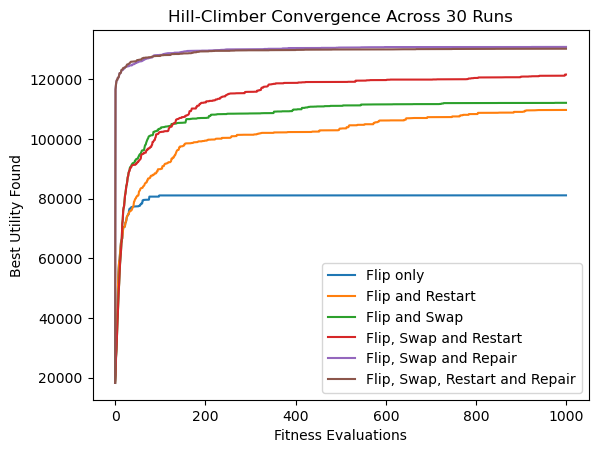

In [20]:
for name, (bestList, traces, solutions, times) in results.items():
    averageTrace = np.mean(traces, axis = 0)
    plt.plot(averageTrace, label = name)
plt.xlabel("Fitness Evaluations")
plt.ylabel("Best Utility Found")
plt.title("Hill-Climber Convergence Across 30 Runs")
plt.legend()
plt.show()

The graph above shows that the flip only is the worst performing Hill-Climber that gets stuck in a local maximum after around 100 to 150 evaluations and is unable to leave. Applying both flip and swap mutations performs better than only flip mutation or flip mutation with restart suggesting that varying the mutation type is better than purely restarting flip mutation. Both Hill-Climbers that introduced repair performed strongly and reached a maximum after around 200 evaluations. 

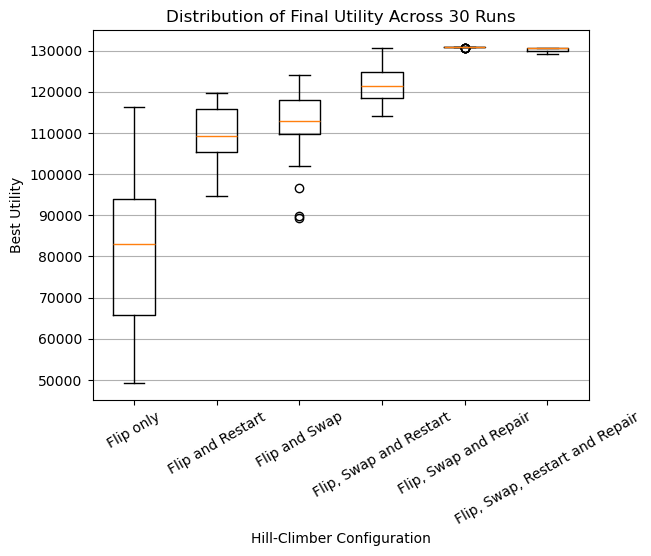

In [21]:
data = [ bestList for bestList, traces, solutions, times in results.values() ]
labels = list(results.keys())
plt.boxplot(data, tick_labels = labels)
plt.xlabel("Hill-Climber Configuration")
plt.ylabel("Best Utility")
plt.title("Distribution of Final Utility Across 30 Runs")
plt.xticks(rotation = 30)
plt.grid(axis="y")
plt.show()

The boxplot above shows that the flip Hill-Climber had the largest range of best utility with the lowest average mean. The best results were found when repair was introduced to the Hill-Climber and suggests that the repair feasibility method works well and consistently returns the same best value.

In [22]:
for name, (bestList, traces, solutions, times) in results.items():
    feasibleCount = 0
    for solution in solutions:
        utility, demand, acceptable = evaluate(solution, capacities, utilities, demands)
        if acceptable:
            feasibleCount += 1
    print(f"{name}: {feasibleCount} / {len(solutions)} solutions are feasible")

Flip only: 30 / 30 solutions are feasible
Flip and Restart: 30 / 30 solutions are feasible
Flip and Swap: 30 / 30 solutions are feasible
Flip, Swap and Restart: 30 / 30 solutions are feasible
Flip, Swap and Repair: 30 / 30 solutions are feasible
Flip, Swap, Restart and Repair: 30 / 30 solutions are feasible


Part One found that the Hill-Climber function performed best when both bit flip and swap mutations were utilised rather than relying on solely one option. Introducing a restart threshold does help the Hill-Climber to escape local maxima for both bit flip alone and when combined with swap mutation. The greatest benefit is found by introducing a feasibility repair function as this consistently returns the best utility. Adding a restart threshold does not help when repair is present and can be detrimental if applied too often in this situation. One downside with repair is that it is computationally more expensive and causes the Hill-Climber to take around four times as long as restarting. As such the best Hill-Climber function likely uses both bit flip and swap mutation with feasibility repair.

PART TWO

Part two aims to implement a population-base metaheurisitic to solve the optimisation problem using instance 2. In contrast to part 1 which searches using the current best solution a population-based algorithm maintains multiple solutions simultaneously. This should allow for the exploration of more search space and the identification of higher quality solutions. The objective is to maximise utility across five different storage capacity constraints. 

In [23]:
if __name__ == "__main__":
    # Example usage demonstration
    sample_file = "multi_resource_n90_m5.txt"
    try:
        n2, m2, utilities2, demands2, capacities2 = load_workload_instance(sample_file)
        print("=== Dataset Ingestion Summary ===")
        print(f"Number of candidate models (n) : {n2}")
        print(f"Number of resource bounds (m)  : {m2}")
        print(f"Utility scores shape (p_j)     : {utilities2.shape}")
        print(f"Resource demands shape (r_ij)  : {demands2.shape}")
        print(f"Capacity limits (b_i)          : {capacities2}")
    except FileNotFoundError:
        print(f"Please provide a valid path to '{sample_file}'.")

=== Dataset Ingestion Summary ===
Number of candidate models (n) : 90
Number of resource bounds (m)  : 5
Utility scores shape (p_j)     : (90,)
Resource demands shape (r_ij)  : (5, 90)
Capacity limits (b_i)          : [2100. 1100. 3300. 3700. 3600.]


In [24]:
#Calculates the total fraction of each capacity required by each model
fractionDemand2 = (demands2 / capacities2[:, None]).sum(axis = 0)
#Calculates the priority sorting ratio by dividing a models utility by capacity demand
ratio2 = utilities2 / fractionDemand2
#Sorts models by priority in descending order(model with highest utility-to-demand first)
modelsByRatio2 = list(np.argsort(-ratio2))

Population and Initialisation

Unlike Part One which represents the search using a single solution, Part Two maintains a population of solutions. Each individual represents a potential solution to the optimisation problem with each position corresponding to a model. Again a 1 indicates a model is deployed and a 0 indicates it is undeployed.

The initial population is generated by randomly creating solutions where each model has an initial 50% probability of being selected. Each individual is then passed through a repair function to ensure that it satisfies all five storage capacities. This provides a starting population of feasible individuals whilst retaining some variation between individuals. 

Population Initialisation Function

In [25]:
def initialisePopulation(popSize, numModels, storageMax, storageReqs, sortedModels):
    """
    Takes in a chosen population size and generates a population of feasible solutions by repairing each solution
    before adding to the population. Returns a population of feasible solutions.
    Input: population size, total number of models, storage capacities, storage demands and a list of models sorted
    by best utility/demand.
    Output: population of feasible situations
    """
    population = []

    for i in range(popSize):
        individual = generateSolution(numModels, 0.5)
        individual = repairSolution(individual, storageMax, storageReqs, sortedModels)
        population.append(individual)
    return population

In [26]:
population = initialisePopulation (100,90, capacities2, demands2, modelsByRatio2)

Checks to make sure initialisePopulation working correctly and all individuals are feasible

In [27]:
print("Population Size:", len(population))
print("Individual Size:", len(population[0]))
print("First Individual", population[0])

Population Size: 100
Individual Size: 90
First Individual [1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 1, 1, 0, 1, 1, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1]


In [28]:
for individual in population:
    utility, demand, acceptable = evaluate(individual, capacities2, utilities2, demands2)
    assert acceptable
print("All individuals are feasible")

All individuals are feasible


Parent Selection

Tournament selection is chosen to select the parents for reproduction. For each selection, a specified number of individuals are randomly sample from the population and the individual with the highest utility is selected as the winner. This process is repeated to select both parents required for crossover.

A larger tournament size increases the likelihood of selecting higher utility solutions, encouraging exploitation of promising solutions. This can reduce population diversity and increase the risk of premature convergence. A smaller tournament size allows weaker solutions a greater chance of being selected to reproduce, thus exploring the space more thoroughly. 

The default size of 3 is used to provide a balance between exploration and exploitation.

Tournament Selection Function

In [29]:
def tournamentSelection(population, totalUtility, tournamentSize = 3):
    """
    Randomly selects tournamentSize individuals and compares them to identify which individual has the best total 
    Utility. This winner is then returned.
    Input: Population of Individuals, Utility of each individual, Number of Individuals to compare.
    Output: Best individual solution
    """
    selected = []
    for i in range(tournamentSize):
        index = rnd.randrange(len(population))
        selected.append(index)
    winner = selected[0]
    for i in selected:
        if totalUtility[i] > totalUtility[winner]:
            winner = i
    return population[winner].copy()

Crossover Functions

Three crossover functions were implemented in Part Two to combine the genetic information from the two parent solutions to provide a child:

One Point Crossover: A random split point is selected within the parent solutions. The child inherits the first section from parent one and the remaining section from parent two. This allows large sections of each parent to be preserved but may limit diversity.

Two Point Crossover: Two random split points are selected with the child inheriting the segment between these points from parent 2. The remaining genetic information is inherited for parent one. The effectiveness of this approach depends heavily on the positions of the crossover points.

Uniform Crossover: Each position in the child is randomly inherited from either parent one or parent two with an equal probability. Unlike One Point and Two Point crossover, this does not preserve sections of genetic information and instead allows the parent models to be mixed more freely, potentially creating greater diversity in the offspring.

Combining Crossover Methods: Implementing all three crossover methods allows for their effectiveness to be compared. This allows the impact of different recombination strategies on solution quality and performance to be investigated.

One Point Crossover Function

In [30]:
def onePointCrossover(parent1, parent2):
    """
    Creates a child that takes the first part of parent1 and the rest from parent2. Point of split is chosen
    at random.
    Input: Two parent solutions
    Output: One child solution
    """
    point = rnd.randint(1,len(parent1) - 1)
    return parent1[:point] + parent2[point:]

Two Point Crossover Function

In [31]:
def twoPointCrossover(parent1, parent2):
    """
    Creates a child that takes a segment of parent2 (between point1 and point2) and the rest from parent1.
    Input: Two parent solutions
    Output: One child solution
    """
    point1 = rnd.randint(1, len(parent1) - 2)
    point2 = rnd.randint(1 + point1 ,len(parent1) - 1)
    return parent1[:point1] + parent2 [point1:point2] + parent1[point2:]

Uniform Crossover Function

In [32]:
def uniformCrossover(parent1, parent2):
    """
    Creates a child where each position i is copied randomly from parent1 or parent2 with equal probability.
    Input: Two parent solutions
    Output: One child solution
    """
    child = []
    for i in range(len(parent1)):
        if rnd.random() < 0.5:
            child.append(parent1[i])
        else:
            child.append(parent2[i])
    return child

Genetic Algorithm

The Genetic Algorithm uses a population based approach to search for high utility solutions. Rather than improving a single solution iteratively, it maintains a population of solutions and generates new solutions through selection, crossover and mutation. This allows for multiple search areas to be explored at the same time which reduces the reliance on a single solution and can potentially avoid local optima.

The algorithm generates an initial population of random solutions which are repaired to ensure they satisfy all capacity requirements. Each solution is evaluated and the best solution found is recorded. Tournament selection then chooses two parents from the population with the solutions with the highest utility in each tournament getting selected. These are then combined using the chosen crossover method. The child solution then has a 25% chance to undergo mutation. If this does happens it is randomly bit flip or swap mutated both with equal probability. This helps introduce additional variation.

The child is then passed through the repair function to make sure it satisfies the capacities. If the child is still under capacity the repair function will deploy additional models as capacity permits. This child is then compared with the worst solution in the population to see which has the higher utility. If the child has higher utility and is not presented in the population this then replaces the worst solution. This replacement strategy maintains the population size and diversity whilst encouraging improvements in overall quality. 

The algorithm will generate and evaluate solutions until the maximum evaluation limit is reached. After this the best utility and solution found throughout the search are retained with a trace that records the best utility after each evaluation. This allows convergence and performance to be assessed across multiple runs.

Constraint Handling

The repair function developed in Part One is reused in the Genetic Algorithm to handle capacity violations. It is applied when generating the starting population and after each new child is produced. This means that the solutions within the population are always feasible and that infeasible children are repaired rather than discarded. This also provides consistency between the Genetic Algorithm and Hill Climber and avoids the need for separate constraint handling strategies.

Genetic Algorithm Function

In [33]:
def geneticAlgorithm (maxEvals, storageMax, storageReqs, utilities, sortedModels, popSize = 100, mutationChance = 0.25,
                       tournamentSize = 3, crossoverType = "uniform"):
    """
    Genetic Algorithm with tournament selection, configurable crossover with adjustable mutation rate and repair.
    Stops after maxEvals number of evaluations by counting all calls to the evaluate function (initial population included)
    Input: Maximum number of evaluations, storage capacities, storage demands, utilities, models ranked by ratio,
    population size, mutation rate, tournament size and crossover type.
    Output: Best utility, the best solution and the trace of best utility after each evaluation
    """
    size = len(utilities)
    population = initialisePopulation(popSize, size, storageMax, storageReqs, sortedModels)
    fitness, trace = [], []
    bestUtility = -1
    bestSolution = None
    for individual in population:
        utility, usage, acceptable = evaluate(individual, storageMax, utilities, storageReqs)
        fitness.append(utility)
        if utility > bestUtility:
            bestUtility, bestSolution = utility, individual.copy()
        trace.append(bestUtility)
    evals = popSize

    while evals < maxEvals:
        parent1 = tournamentSelection(population, fitness, tournamentSize)
        parent2 = tournamentSelection(population, fitness, tournamentSize)
        if crossoverType == "uniform":
            child = uniformCrossover(parent1,parent2)
        elif crossoverType == "one point":
            child = onePointCrossover(parent1,parent2)
        else:
            child = twoPointCrossover(parent1,parent2)
        if rnd.random() < mutationChance:
            if rnd.random() < 0.5:
                child = createNeighbour(child)
            else:
                child = swapMutation(child)
        child = repairSolution(child, storageMax, storageReqs, sortedModels)
        utility, usage, acceptable = evaluate(child, storageMax, utilities, storageReqs)
        evals += 1
        worst = int(np.argmin(fitness))
        if utility >= fitness[worst] and child not in population:
            population[worst] = child
            fitness[worst] = utility
        if utility > bestUtility:
            bestUtility, bestSolution = utility, child.copy()
        trace.append(bestUtility)
    return bestUtility, bestSolution, trace[:maxEvals]

PART TWO EXPERIMENT

To evaluate the performance a series of experiments were conducted on Instance Two (90 models and five capacity constraints). Firstly the three different crossover configurations were compared on the base Genetic Algorithm to identify the best candidate. The three strategies were:

1. Uniform Crossover
2. One Point Crossover
3. Two Point Crossover

Each configuration was evaluated across 30 runs using random seed 42 as the starting seed for  reproducibility. All configurations used the maximum evaluation limit of 1000 with the same population size, mutation probability, and tournament size to ensure fair comparison. Performance is assessed using minimum utility, maximum utility, mean utility, standard deviation and execution time across runs. 

The best strategy will then be taken forward to identify the best parameters for mutation probability, tournament size and population size. This will then be compared against the base Genetic Algorithm for that strategy and the Hill Climber from Part One.

This aims to investigate the effect of different crossover strategies on Genetic Algorithm performance and assess whether a tuned population based approach can achieve better solutions than a Hill Climber in the larger optimisation area. 

In [34]:
def runExperimentGA (maxEvals, storageMax, storageReqs, utilities, sortedModels, popSize = 100, mutationChance = 0.25,
                       tournamentSize = 3, crossoverType = "uniform", numRuns = 30):
    """
    Runs the genetic algorithm numRuns times, each with its own seed (starting seed set to 42 for replicability) and each time 
    with the same maximum number of evaluations to ensure comparisons are fair.

    Input: Maximum number of evaluations, storage capacities, storage demands, utilities, models ranked by ratio,
    population size, mutation rate, crossover type and number of runs.

    Outputs: Arrays for best utilities, traces, best solutions and run times.
    """
    bestList, traces, times, solutions = [], [], [], []
    for run in range(numRuns):
        np.random.seed (42 + run)
        rnd.seed(42 + run)
        start = time.time()
        best, solution, trace = geneticAlgorithm(maxEvals, storageMax, storageReqs, utilities, sortedModels, popSize, mutationChance,
                                                      tournamentSize, crossoverType)
        times.append(time.time() - start)
        bestList.append(best)
        traces.append(trace)
        solutions.append(solution)
    return np.array(bestList), np.array(traces), np.array(solutions), np.array(times)

In [35]:
resultsGA = {}
resultsGA ["Uniform Crossover"] = runExperimentGA (1000, capacities2, demands2, utilities2, modelsByRatio2)
resultsGA ["One Point Crossover"] = runExperimentGA (1000, capacities2, demands2, utilities2, modelsByRatio2, crossoverType = "one point")
resultsGA ["Two Point Crossover"] = runExperimentGA (1000, capacities2, demands2, utilities2, modelsByRatio2, crossoverType = "two point")

In [36]:
for name, (bestList, traces, solutions, times) in resultsGA.items():
    print(f"{name}, Maximum Utility = {np.max(bestList)}, Minimum Utility = {np.min(bestList)}, \nMean Utility = {np.mean(bestList):.2f}"
          f" Standard Deviation = {np.std(bestList):.2f}, Max Time: {np.max(times):.2f} seconds")

Uniform Crossover, Maximum Utility = 11191.0, Minimum Utility = 11165.0, 
Mean Utility = 11188.57 Standard Deviation = 6.59, Max Time: 0.41 seconds
One Point Crossover, Maximum Utility = 11191.0, Minimum Utility = 11162.0, 
Mean Utility = 11183.03 Standard Deviation = 10.52, Max Time: 0.40 seconds
Two Point Crossover, Maximum Utility = 11191.0, Minimum Utility = 11146.0, 
Mean Utility = 11177.93 Standard Deviation = 13.37, Max Time: 0.47 seconds


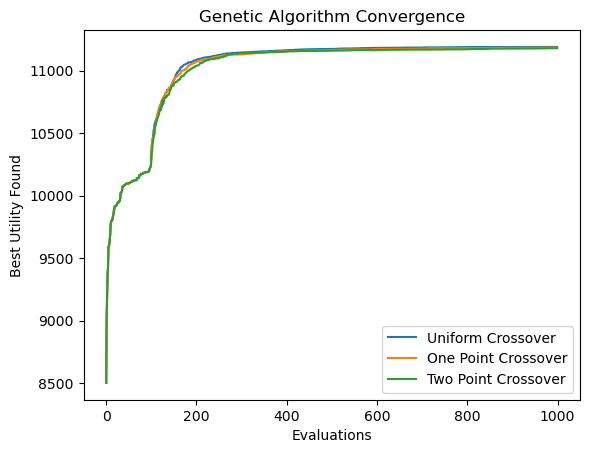

In [37]:
for name, (bestList, traces, solutions, times) in resultsGA.items():
    averageTrace = np.mean(traces, axis = 0)
    plt.plot(averageTrace, label = name)
plt.xlabel("Evaluations")
plt.ylabel("Best Utility Found")
plt.title("Genetic Algorithm Convergence")
plt.legend()
plt.show()

The results indicate that Uniform Crossover performed best overall, achieving the highest mean utility of 11188.57 across the 30 runs with the lowest standard deviation of 6.59 suggesting that it consistently generated high utility solutions with little variation between runs. Although all crossover methods reach the same maximum utility of 11191, Uniform Crossover had the highest minimum utility at 11165.

These results suggest that Uniform Crossover is more effective for this Instance. By independently selecting each model from either parent, it allows greater flexibility when combining different model selections rather than preserving consecutive sections of genetic code.

Next the mutation rate, tournament size and population size were varied to find which values gave the strongest performance.

In [38]:
mutationResults = {}
for muteRate in [0.1, 0.25, 0.4, 0.5, 0.75, 0.8]:
    mutationResults[muteRate] = runExperimentGA(1000, capacities2, demands2, utilities2, modelsByRatio2,mutationChance = muteRate)


In [39]:
for name, (bestList, traces, solutions, times) in mutationResults.items():
    print(f"{name}, Maximum Utility = {np.max(bestList)}, Minimum Utility = {np.min(bestList)}, \nMean Utility = {np.mean(bestList):.2f}"
          f" Standard Deviation = {np.std(bestList):.2f}, Max Time: {np.max(times):.2f} seconds")

0.1, Maximum Utility = 11191.0, Minimum Utility = 11182.0, 
Mean Utility = 11189.87 Standard Deviation = 2.50, Max Time: 0.40 seconds
0.25, Maximum Utility = 11191.0, Minimum Utility = 11165.0, 
Mean Utility = 11188.57 Standard Deviation = 6.59, Max Time: 0.41 seconds
0.4, Maximum Utility = 11191.0, Minimum Utility = 11187.0, 
Mean Utility = 11190.33 Standard Deviation = 1.49, Max Time: 0.41 seconds
0.5, Maximum Utility = 11191.0, Minimum Utility = 11170.0, 
Mean Utility = 11190.17 Standard Deviation = 3.81, Max Time: 0.42 seconds
0.75, Maximum Utility = 11191.0, Minimum Utility = 11182.0, 
Mean Utility = 11190.00 Standard Deviation = 2.45, Max Time: 0.42 seconds
0.8, Maximum Utility = 11191.0, Minimum Utility = 11182.0, 
Mean Utility = 11190.43 Standard Deviation = 1.86, Max Time: 0.41 seconds


Six mutation probabilities were tested: 0.1, 0.25, 0.4, 0.5, 0.75, and 0.8. All other parameters were kept constant and each configuration was evaluated across 30 runs using the same starting seed.

The results showed that the mutation probability of 0.4 achieved the second highest mean utility at 11190.33, alongside the lowest standard deviation of 1.49. It also achieved a minimum utility of 1187 thus demonstrating consistent performance across all 30 runs. In comparison, the original mutation probability of 0.25 achieved a mean utility of 11188.57 and a standard deviation of 6.59.

These results suggest that increasing the mutation probability to 0.4 improves average solution quality and consistency. A higher mutation probability likely provides a greater chance of variance being introduced to the population allowing the algorithm to explore alternative combinations. 

Although a mutation rate of 0.8 did have a slightly higher mean utility at 11190.43, both the mean time taken and standard deviation were also higher. As such 0.4 was selected as the preferred mutation probability.


In [40]:
tournamentResults = {}
for tournament in [2, 3, 4, 5, 7, 10]:
    tournamentResults[tournament] = runExperimentGA(1000, capacities2, demands2, utilities2, modelsByRatio2,mutationChance = 0.4, tournamentSize = tournament)


In [41]:
for name, (bestList, traces, solutions, times) in tournamentResults.items():
    print(f"{name}, Maximum Utility = {np.max(bestList)}, Minimum Utility = {np.min(bestList)}, \nMean Utility = {np.mean(bestList):.2f}"
          f" Standard Deviation = {np.std(bestList):.2f}, Max Time: {np.max(times):.2f} seconds")

2, Maximum Utility = 11191.0, Minimum Utility = 11178.0, 
Mean Utility = 11189.40 Standard Deviation = 3.50, Max Time: 0.42 seconds
3, Maximum Utility = 11191.0, Minimum Utility = 11187.0, 
Mean Utility = 11190.33 Standard Deviation = 1.49, Max Time: 0.43 seconds
4, Maximum Utility = 11191.0, Minimum Utility = 11164.0, 
Mean Utility = 11188.00 Standard Deviation = 7.43, Max Time: 0.48 seconds
5, Maximum Utility = 11191.0, Minimum Utility = 11182.0, 
Mean Utility = 11190.17 Standard Deviation = 2.03, Max Time: 0.41 seconds
7, Maximum Utility = 11191.0, Minimum Utility = 11182.0, 
Mean Utility = 11189.50 Standard Deviation = 3.35, Max Time: 0.41 seconds
10, Maximum Utility = 11191.0, Minimum Utility = 11156.0, 
Mean Utility = 11187.23 Standard Deviation = 8.52, Max Time: 0.40 seconds


Following the mutation probability experiment, further experiments were conducted to investigate the effect of tournament size on Genetic Algorithm performance. A mutation probability of 0.4 and Uniform Crossover were retained based on previous experiments.

Six tournament sizes were tested: 2, 3, 4, 5, 7, and 10 with all other parameters constant, across 30 runs of 1000 max evaluations.

These results showed that a tournament size of 3 achieved the highest mean utility of 11190.33 and the lowest standard deviation of 1.49. It also achieved the highest minimum utility at 11187 showing consistently strong performance.

Larger tournament sizes did not improve performance with tournament size 10 having the lowest mean utility and highest standard deviation. This suggests that excessive selection pressure reduces population diversity leading to premature convergence.

Overall tournament size 3 was selected as the preferred configuration.

In [42]:
populationResults = {}
for pop in [25, 50, 75, 100, 150, 200]:
    populationResults[pop] = runExperimentGA(1000, capacities2, demands2, utilities2, modelsByRatio2,mutationChance = 0.4, popSize = pop)


In [43]:
for name, (bestList, traces, solutions, times) in populationResults.items():
    print(f"{name}, Maximum Utility = {np.max(bestList)}, Minimum Utility = {np.min(bestList)}, \nMean Utility = {np.mean(bestList):.2f}"
          f" Standard Deviation = {np.std(bestList):.2f}, Max Time: {np.max(times):.2f} seconds")

25, Maximum Utility = 11191.0, Minimum Utility = 11162.0, 
Mean Utility = 11187.23 Standard Deviation = 8.28, Max Time: 0.39 seconds
50, Maximum Utility = 11191.0, Minimum Utility = 11182.0, 
Mean Utility = 11190.40 Standard Deviation = 2.24, Max Time: 0.40 seconds
75, Maximum Utility = 11191.0, Minimum Utility = 11169.0, 
Mean Utility = 11189.40 Standard Deviation = 4.48, Max Time: 0.40 seconds
100, Maximum Utility = 11191.0, Minimum Utility = 11187.0, 
Mean Utility = 11190.33 Standard Deviation = 1.49, Max Time: 0.41 seconds
150, Maximum Utility = 11191.0, Minimum Utility = 11161.0, 
Mean Utility = 11185.10 Standard Deviation = 9.16, Max Time: 0.42 seconds
200, Maximum Utility = 11191.0, Minimum Utility = 11169.0, 
Mean Utility = 11185.33 Standard Deviation = 7.80, Max Time: 0.43 seconds


The next experiment examined population size. Six population sizes were investigated: 25, 50, 75, 100, 150, and 200. All experiments used a maximum limit of 1000 evaluations and 30 runs.

The results showed that population size of 50 achieved the highest mean utility at 11190.40 and was closely followed by a population size of 100 at 11190.33. The population size of 100 had a lower standard deviation at 1.49 and the highest minimum utility at 11187, indicating more consistent performance over the 30 runs.

Larger population produced lower mean utilities at 11185.1 and 11185.33 respectively. This may be down to a larger proportion of the evaluation budget being used when initialising the population, leaving fewer evaluation for generating offspring and improving solutions. Conversely, the smaller populations appear to not provide sufficient diversity for exploration.

The population size of 100 was chosen as the preferred configuration due to its low standard deviation and stronger worse-case performance suggesting a stronger balance between solution quality and consistency.

In [44]:
resultsPartTwo = {}
resultsPartTwo ["Uniform Crossover Baseline"] = runExperimentGA (1000, capacities2, demands2, utilities2, modelsByRatio2)
resultsPartTwo ["Uniform Crossover Tuned"] = runExperimentGA (1000, capacities2, demands2, utilities2, modelsByRatio2, mutationChance = 0.4, popSize = 100)
resultsPartTwo ["Hill Climber Repair"] = runExperiment(capacities2, demands2, utilities2, modelsByRatio2, swap = True, repair = True, maxEvals = 1000)

In [45]:
for name, (bestList, traces, solutions, times) in resultsPartTwo.items():
    print(f"{name}, Maximum Utility = {np.max(bestList)}, Minimum Utility = {np.min(bestList)}, \nMean Utility = {np.mean(bestList):.2f}"
          f" Standard Deviation = {np.std(bestList):.2f}, Max Time: {np.max(times):.2f} seconds")

Uniform Crossover Baseline, Maximum Utility = 11191.0, Minimum Utility = 11165.0, 
Mean Utility = 11188.57 Standard Deviation = 6.59, Max Time: 0.41 seconds
Uniform Crossover Tuned, Maximum Utility = 11191.0, Minimum Utility = 11187.0, 
Mean Utility = 11190.33 Standard Deviation = 1.49, Max Time: 0.41 seconds
Hill Climber Repair, Maximum Utility = 11191.0, Minimum Utility = 11130.0, 
Mean Utility = 11171.20 Standard Deviation = 18.12, Max Time: 0.37 seconds


Final Algorithm Comparisons

Parameter Tuning Improves Performance

the turned Genetic increased mean utility from 11188.57 to 11190.33. This is an improvement of 1.76 utility. The standard deviation also decrease from 6.59 to 1.49, further reinforcing the idea of greater consistency across runs. 

An increase in minimum utility was also found from 11165 to 11187.

this suggests that increasing the mutation probability from 0.25 to 0.4 improved the algorithm's performance.

Genetic Algorithm vs Hill Climber

The tuned Genetic Algorithm achieved a mean utility of 11190.33 compared with 11171.20 for the Hill Climber. This represents an improvement of 19.13 in mean utility.

The tuned Genetic Algorithm also had a considerably lower reduction in standard deviation:

Tuned GA:1.49 

Hill Climber:18.12 

This is an over 90% reduction in standard deviation. 

The Hill Climber was marginally fast with an average execution time of 0.37s compared to 0.42s for the tuned Genetic Algorithm. Although this difference is relatively small for the improvement in overall solution quality and consistency.

Overall the tuned Genetic Algorithm provided the strongest performance, demonstrating that a population based approach combined with appropriate crossover, mutation rate and selection parameters was more effective for tackling this larger optimisation instance.

PART 3

All of the Genetic Algorithms in Part 2 and the Hill-Climber reach a maximum utility of 11191 and are unable to improve. It would appear that the capacities are limiting the utility from increasing. The code below checks what percentage of each capacity is used in each of the Genetic Algorithms and the Hill Climber in the experiment at the end of part two.

In [46]:
for name in ["Uniform Crossover Baseline", "Uniform Crossover Tuned", "Hill Climber Repair"]:
    solutions = resultsPartTwo[name][2]
    totalUsage = 100 * np.array([np.dot(demands2, individual) / capacities2 for individual in solutions])
    print(f"{name}: mean % of each capacity used = {np.round(totalUsage.mean(axis = 0), 1)}, lowest = {np.round(totalUsage.min(axis = 0),1)}")

Uniform Crossover Baseline: mean % of each capacity used = [ 84.5 100.   68.   59.8  67.3], lowest = [82.4 99.9 63.6 55.7 67.2]
Uniform Crossover Tuned: mean % of each capacity used = [ 84.5 100.   68.4  60.3  67.2], lowest = [82.9 99.9 66.3 57.7 66.6]
Hill Climber Repair: mean % of each capacity used = [ 84.3 100.   66.1  57.5  67.7], lowest = [81.8 99.6 63.6 55.6 66.2]


The code above shows that resource two consistently bottlenecks all 3 of the metaheuristics with capacity one in second place with around 85% storage used. As such it is possible that a solution that gives greater weighting to the second resource could provide a solution with better utility or that reaches the assumed global maximum faster.

Empirical Study and Hypothesis Testing

For Part 3 an investigation will be undertaken into alternative weighting strategies for the five capacities within the instance, with the aim of identifying whether different weight distributions can improve the algorithms performance and efficiency.

Four weighting strategies will be investigated: equal weighting (baseline), Usage based weighting, oversubscription based weighting and a reduction strategy. The reduction strategy will assign a significantly higher weight to Capacity two, a moderately higher weigh to Capacity one, and lower weights across the remaining capacities.


Hypothesis:
By utilising a weighting strategy that increases the relative weighting of heavily used resource constraints, the Genetic Algorithm's repair function will make more informed decisions when removing models from infeasible solutions. This is expected increase the final utility and converge towards maximum utility in fewer fitness evaluations than the equal weighting strategy.

In [47]:
allModelCapacity = demands2.sum(axis=1) / capacities2
print("total demand over capacity for each capacity: ", np.round(allModelCapacity, 2))
print("mean demand per model over capacity: ", np.round(demands2.mean(axis = 1) / capacities2, 2))

total demand over capacity for each capacity:  [1.58 3.06 1.17 1.05 1.1 ]
mean demand per model over capacity:  [0.02 0.03 0.01 0.01 0.01]


In [48]:
def modelPrioritySort(utilities, storageReqs, storageMax, weighting):
    
    weightedDemand = (weighting[:, None] * storageReqs / storageMax[:, None]).sum(axis = 0)
    return list(np.argsort(-(utilities/weightedDemand)))
    

In [49]:
print(totalUsage.mean(axis = 0))
normalOrder = modelPrioritySort(utilities2, demands2, capacities2, np.ones(5))
priorities = totalUsage.mean(axis = 0)
weighting = priorities / priorities.mean()
weightedOrder = modelPrioritySort(utilities2, demands2, capacities2, weighting)
print(normalOrder)
print(weightedOrder)

[84.33968254 99.95454545 66.12121212 57.49369369 67.67222222]
[30, 62, 10, 0, 12, 11, 42, 6, 17, 49, 22, 4, 47, 84, 29, 69, 48, 85, 68, 41, 58, 15, 65, 61, 66, 34, 38, 55, 72, 75, 21, 53, 50, 59, 3, 18, 25, 73, 80, 60, 78, 32, 81, 70, 79, 8, 86, 87, 20, 9, 51, 74, 33, 57, 89, 24, 37, 52, 1, 14, 16, 5, 39, 40, 88, 54, 77, 82, 67, 27, 28, 13, 2, 7, 26, 76, 36, 23, 63, 31, 35, 46, 44, 43, 83, 71, 19, 56, 64, 45]
[62, 30, 0, 10, 6, 11, 12, 42, 17, 22, 4, 49, 47, 29, 84, 41, 69, 48, 85, 68, 65, 15, 61, 55, 38, 72, 66, 34, 58, 75, 21, 50, 18, 59, 53, 25, 60, 3, 73, 81, 8, 87, 32, 78, 86, 79, 51, 9, 70, 80, 33, 57, 74, 20, 89, 14, 24, 39, 1, 37, 77, 5, 52, 54, 16, 82, 40, 88, 67, 27, 13, 28, 2, 63, 23, 36, 26, 7, 76, 31, 46, 35, 44, 43, 71, 83, 19, 56, 64, 45]


Weighting Strategies

Four different weighting strategies were investigated to determine whether altering the importance of the five capacities would have an improvement on algorithm performance.

Equal Weighting - The first strategy assigns each capacity a weight of 1 and is the baseline used in Part 2 and provides a baseline to compare alternative weightings against.

Usage Based Weighting - This calculates the average usage of each of the five capacities and normalises them by dividing average usage in that capacity over the overall average use for all five capacities to provide a relative weighting.

Oversubscription Based Weighting - This calculates the weightings by calculating the ratio of total demand to available capacity for each capacity. these ratios are normalised by diving by the average ratio across all capacities to provide relative weights where capacities with high oversubscription receive greater weights.

Reduction Based Weighting - This calculates the weighting of the capacities as a proportion of the demand that would need to be removed from each capacity for demand to fit within capacity. This is done by calculating 1 - 1/r with r being the ratio of total demand to capacity. Again the values are normalised using their means to provide the relative weights. This allows for capacities with higher levels of oversubscription to receive higher weights.

In [50]:
fractionToRemove = np.maximum(1 - 1/allModelCapacity, 0.01)
weightingOptions = { "equal": np.ones(5),
                    "Usage Based": weighting,
                    "Oversubscription": allModelCapacity / allModelCapacity.mean(),
                    "Reduction": fractionToRemove/ fractionToRemove.mean()
                   }
randoms=[]
for i in range(1000):
    randoms.append(generateSolution(n2, 0.5))
base = modelPrioritySort(utilities2, demands2, capacities2, weightingOptions["equal"])
for name,weightMethod in weightingOptions.items():
    order = modelPrioritySort(utilities2, demands2, capacities2, weightMethod)
    correlation = np.corrcoef(np.argsort(base),np.argsort(order))[0,1]
    fixed = []
    for solution in randoms:
        fixed.append(repairSolution(solution, capacities2, demands2, order))
    utilityList = []
    for item in fixed:
        utilityList.append(np.dot(utilities2, item))
    utilityMean = np.mean(utilityList)
    changedList = []
    for solution, fixedSolution in zip(randoms,fixed):
        count = 0
        for positionSol, positionfixed in zip(solution, fixedSolution):
            if positionSol != positionfixed:
                count += 1
        changedList.append(count)
    changedMean = np.mean(changedList)
    print(f"{name:19s} weights = {np.round(weightMethod, 2)} rank correlation vs equal = {correlation:.4f} "
        f"utility after repair = {utilityMean:.0f} positions changed = {changedMean}")

equal               weights = [1. 1. 1. 1. 1.] rank correlation vs equal = 1.0000 utility after repair = 8340 positions changed = 18.21
Usage Based         weights = [1.12 1.33 0.88 0.77 0.9 ] rank correlation vs equal = 0.9942 utility after repair = 8385 positions changed = 17.738
Oversubscription    weights = [0.99 1.92 0.74 0.66 0.69] rank correlation vs equal = 0.9810 utility after repair = 8433 positions changed = 17.381
Reduction           weights = [1.38 2.54 0.56 0.18 0.34] rank correlation vs equal = 0.9606 utility after repair = 8458 positions changed = 17.406


Following the initial comparison, usage based weighting was excluded from further investigation as it provided a relatively small increase to utility in comparison with the other two weighting methods.

Comparison of Oversubscription and Reduction: Both weighting strategies are based on the total demand to capacity ratio but calculate their weightings differently. Oversubscription utilises this directly which means the weights increase propotionally with the level of oversubscription. Reduction on the other hand calculates how much demand (as a proportion) that would need to be removed to make each capacity to reach the limits. This leads to reduction placing a far lesser emphasis on the weightings for capacities that are only slightly oversubscribed whilst retaining the emphasis on those requiring large reductions in demand.

In [51]:
overSubscriptionWeights = allModelCapacity / allModelCapacity.mean()
reductionWeights = fractionToRemove/fractionToRemove.mean()
equalOrder = modelPrioritySort(utilities2, demands2, capacities2, np.ones(5))
overSubscriptionOrder = modelPrioritySort(utilities2, demands2, capacities2, overSubscriptionWeights)
reductionOrder = modelPrioritySort(utilities2, demands2, capacities2, reductionWeights)

In [52]:
budget = 1000
comparison = {}
comparison ["Equal Weighting"] = runExperimentGA (budget, capacities2, demands2, utilities2, equalOrder, numRuns = 30, mutationChance = 0.4)
comparison ["Oversubscription Weighting"] = runExperimentGA (budget, capacities2, demands2, utilities2, overSubscriptionOrder, numRuns = 30, mutationChance = 0.4)
comparison ["Reduction Weighting"] = runExperimentGA (budget, capacities2, demands2, utilities2, reductionOrder, numRuns = 30, mutationChance = 0.4)

In [53]:
bestFound = 0
for utility in comparison.values():
    currentBest = utility[0].max()
    if currentBest > bestFound:
        bestFound = currentBest
aim = 0.9999 * bestFound
evaluationsNeeded = {}
for name, (bestList, traces, solutions, times) in comparison.items():
    needed = []
    for trace in traces:
        achieved = np.where(trace >= aim)[0]
        if len(achieved) > 0:
            needed.append(achieved[0] + 1)
        else:
            needed.append(budget + 1)
    evaluationsNeeded[name] = np.array(needed)
for name, (bestList, traces, solutions, times) in comparison.items():
    reachedCount = 0
    for evaluation in evaluationsNeeded[name]:
        if evaluation <= budget:
            reachedCount = reachedCount + 1
    meanResult = bestList.mean()
    stdResult = bestList.std()
    maxResult = bestList.max()
    minResult = bestList.min()
    totalRuns = len(bestList)
    medianEvaluations = np.median(evaluationsNeeded[name])
    meanBestSoFar = traces.mean()
    averageTime = times.mean()
    print(f"{name:20s}\nFinal: Mean = {meanResult:.0f}, std = {stdResult:.2f}, max = {maxResult:.1f}, min = {minResult:.1f}"
    f"\nReached Target in {reachedCount}/{totalRuns} runs, Median Evaluations = {medianEvaluations:.0f} trace mean = {meanBestSoFar:.0f}"
    f"\nTime Taken = {averageTime:.3f}s")

Equal Weighting     
Final: Mean = 11190, std = 1.49, max = 11191.0, min = 11187.0
Reached Target in 25/30 runs, Median Evaluations = 689 trace mean = 11023
Time Taken = 0.397s
Oversubscription Weighting
Final: Mean = 11191, std = 0.72, max = 11191.0, min = 11187.0
Reached Target in 29/30 runs, Median Evaluations = 406 trace mean = 11056
Time Taken = 0.392s
Reduction Weighting 
Final: Mean = 11191, std = 0.00, max = 11191.0, min = 11191.0
Reached Target in 30/30 runs, Median Evaluations = 438 trace mean = 11062
Time Taken = 0.390s


Exploratory phase compared Equal, Oversubscription and Reduction weightings. A maximum value of 11191 was found across the models and only Reduction weighting was able to reach this every time. Coupling this with a standard deviation of 0 suggests this may be the best performing weighting.

Oversubscription weighting does reach the target in a lower median number of evaluations (406) compared to Reduction (438). This suggests that although Reduction is more consistent, Oversubscription converges faster. Equal weighting performed least effective across all metrics having a median number of evaluations of 689.

Based on these results, Reduction weighting is the preferred strategy due to its consistent achievement of maximum observed utility. However, Oversubscription could be a competitive alternative if faster convergence is required.

A final experiment will be conducted using 100 independent runs to provide a larger sample size and investigate whether these differences in performance remain constant between Equal Weighting and Reduction Weighting.

In [54]:
budget = 1000
resultsPart3 = {}
resultsPart3 ["Equal Weighting"] = runExperimentGA (budget, capacities2, demands2, utilities2, equalOrder, numRuns = 100, mutationChance = 0.4)
resultsPart3 ["Reduction Weighting"] = runExperimentGA (budget, capacities2, demands2, utilities2, reductionOrder, numRuns = 100, mutationChance = 0.4)

In [55]:
bestFound = 0
for utility in resultsPart3.values():
    currentBest = utility[0].max()
    if currentBest > bestFound:
        bestFound = currentBest
aim = 0.9999 * bestFound
evaluationsNeeded = {}
for name, (bestList, traces, solutions, times) in resultsPart3.items():
    needed = []
    for trace in traces:
        achieved = np.where(trace >= aim)[0]
        if len(achieved) > 0:
            needed.append(achieved[0] + 1)
        else:
            needed.append(budget + 1)
    evaluationsNeeded[name] = np.array(needed)
for name, (bestList, traces, solutions, times) in resultsPart3.items():
    reachedCount = 0
    for evaluation in evaluationsNeeded[name]:
        if evaluation <= budget:
            reachedCount = reachedCount + 1
    meanResult = bestList.mean()
    stdResult = bestList.std()
    maxResult = bestList.max()
    minResult = bestList.min()
    totalRuns = len(bestList)
    medianEvaluations = np.median(evaluationsNeeded[name])
    meanBestSoFar = traces.mean()
    averageTime = times.mean()
    print(f"{name:20s}\nFinal: Mean = {meanResult:.0f}, std = {stdResult:.2f}, max = {maxResult:.1f}, min = {minResult:.1f}"
    f"\nReached Target in {reachedCount}/{totalRuns} runs, Median Evaluations = {medianEvaluations:.0f} trace mean = {meanBestSoFar:.0f}"
    f"\nTime Taken = {averageTime:.3f}s")

Equal Weighting     
Final: Mean = 11190, std = 3.05, max = 11191.0, min = 11165.0
Reached Target in 87/100 runs, Median Evaluations = 704 trace mean = 11033
Time Taken = 0.401s
Reduction Weighting 
Final: Mean = 11191, std = 0.40, max = 11191.0, min = 11187.0
Reached Target in 99/100 runs, Median Evaluations = 452 trace mean = 11061
Time Taken = 0.390s


Reduction Weighting continue to perform better than Equal weighting with a mean utility of 11191 and a standard deviation of 0.4. It also reached 99.99% of the maximum observed utility in 99 out of 100 runs with that one run reaching 11187 utility. In comparison Equal weighting had a mean utility of 11190 with a standard deviation of 3.05. Equal weighting only reached 99.99% of the maximum observed value in 87 of the 100 runs.

Reduction Weighting also converged much faster reaching the target in a median of 452 evaluations versus 704 evaluations for Equal Weighting. This represents a reduction of around 36% in the number of evaluations required compared to equal weighting. Reduction Weighting was also slightly faster at a mean time of 0.394s against Equal Weightings 0.406s.

This would suggest that reduction weighting performs better and more efficiently than the Equal Weighting. To confirm whether this is a statistically significant finding A Wilcoxon signed-rank test was conducted. A Wilcoxon signed-rank test was selected because the experiments were conducted using corresponding random seeds on the same Instance. This allows results to be compared in pairs without assuming that the differences follow a normal distribution.

The test uses a significance level of 0.05. A p-value below 0.05 indicates that there is sufficient evidence that the null hypothesis can be rejected.

Two tests were performed. The first compared the total utility achieved by each weighing strategy to see if there was a statistically significant difference in model performance. The second compared the number of evaluations required to converge to investigate whether there was a significant difference in model efficiency.

In [56]:
equal = resultsPart3["Equal Weighting"][0]
reduct = resultsPart3["Reduction Weighting"][0]

statistic, p = wilcoxon(equal, reduct)
print("Wilcoxon Statistic:", statistic)
print("p-value:", p)

Wilcoxon Statistic: 6.0
p-value: 0.001986261087870335


As the p-value is less than 0.05 we are able to reject the null hypothesis.

Combined with the descriptive statistics above this statistically supports the hypothesis that utilising Reduction Weighting provides a better maximum utility than Equal Weighting. It should be noted that whilst this is statistically significant the overall difference is small.

In [57]:
equalEvals = evaluationsNeeded["Equal Weighting"]
reductEvals = evaluationsNeeded["Reduction Weighting"]
statistic, p = wilcoxon(equalEvals, reductEvals)
print("Wilcoxon Statistic:", statistic)
print("p-value:", p)

Wilcoxon Statistic: 464.5
p-value: 2.2623595296352518e-12


As the p-value is less than 0.05 we are able to reject the null hypothesis.

Combined with the descriptive statistics above this statistically supports the hypothesis that utilising Reduction Weighting provides a more efficient Genetic Algorithm than Equal Weighting.

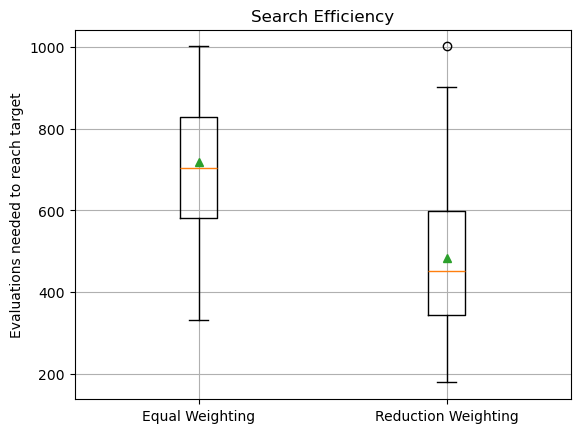

In [58]:
plt.boxplot(
            [equalEvals, reductEvals], 
            tick_labels = ["Equal Weighting", "Reduction Weighting"], 
            showmeans = True
           )
plt.ylabel("Evaluations needed to reach target")
plt.title("Search Efficiency")
plt.grid()
plt.show()

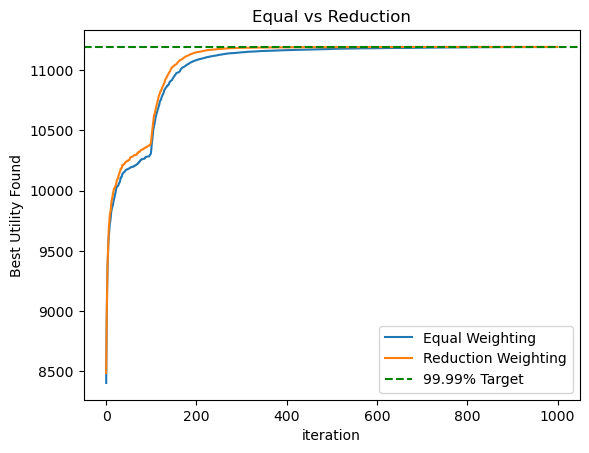

In [59]:
for name, (bestList, traces, solutions, times) in resultsPart3.items():
    averageTrace = np.mean(traces, axis = 0)
    plt.plot(averageTrace, label = name)
plt.xlabel("iteration")
plt.ylabel("Best Utility Found")
plt.title("Equal vs Reduction")
plt.axhline(y=aim, color="green", linestyle="--", label= "99.99% Target")
plt.legend()
plt.show()

Part 3 Findings

Reduction Weighting reached 99.99% of the maximum observed utility in 99/100 runs compared to 87/100 runs for Equal Weighting. This also only needed a median of 452 evaluations compared to the 704 for Equal Weighting, representing about a 36% reduction in evaluations. The final mean utility was also higher at 11191 (std 0.4) compared to 11190 (std 3.05). Both results were found to be statistically significant using the Wilcoxon signed-rank so the hypothesis that changing the weighting to put more attention on capacities that are oversubscribed does lead to a Genetic Algorithm that is more efficient and performs better. 

Although the improvement in mean utility is relatively small, the substantial reduction in evaluations required and the greater consistency across runs suggests that the main benefit of Reduction Weighting is improving the speed and reliability of the Genetic Algorithm.

[1]P.C. Chu and J.E. Beasley A genetic Algorithm for the Multidimensional Knapsack Problem Journal of Heuristics vol.4 pg63 - 86 